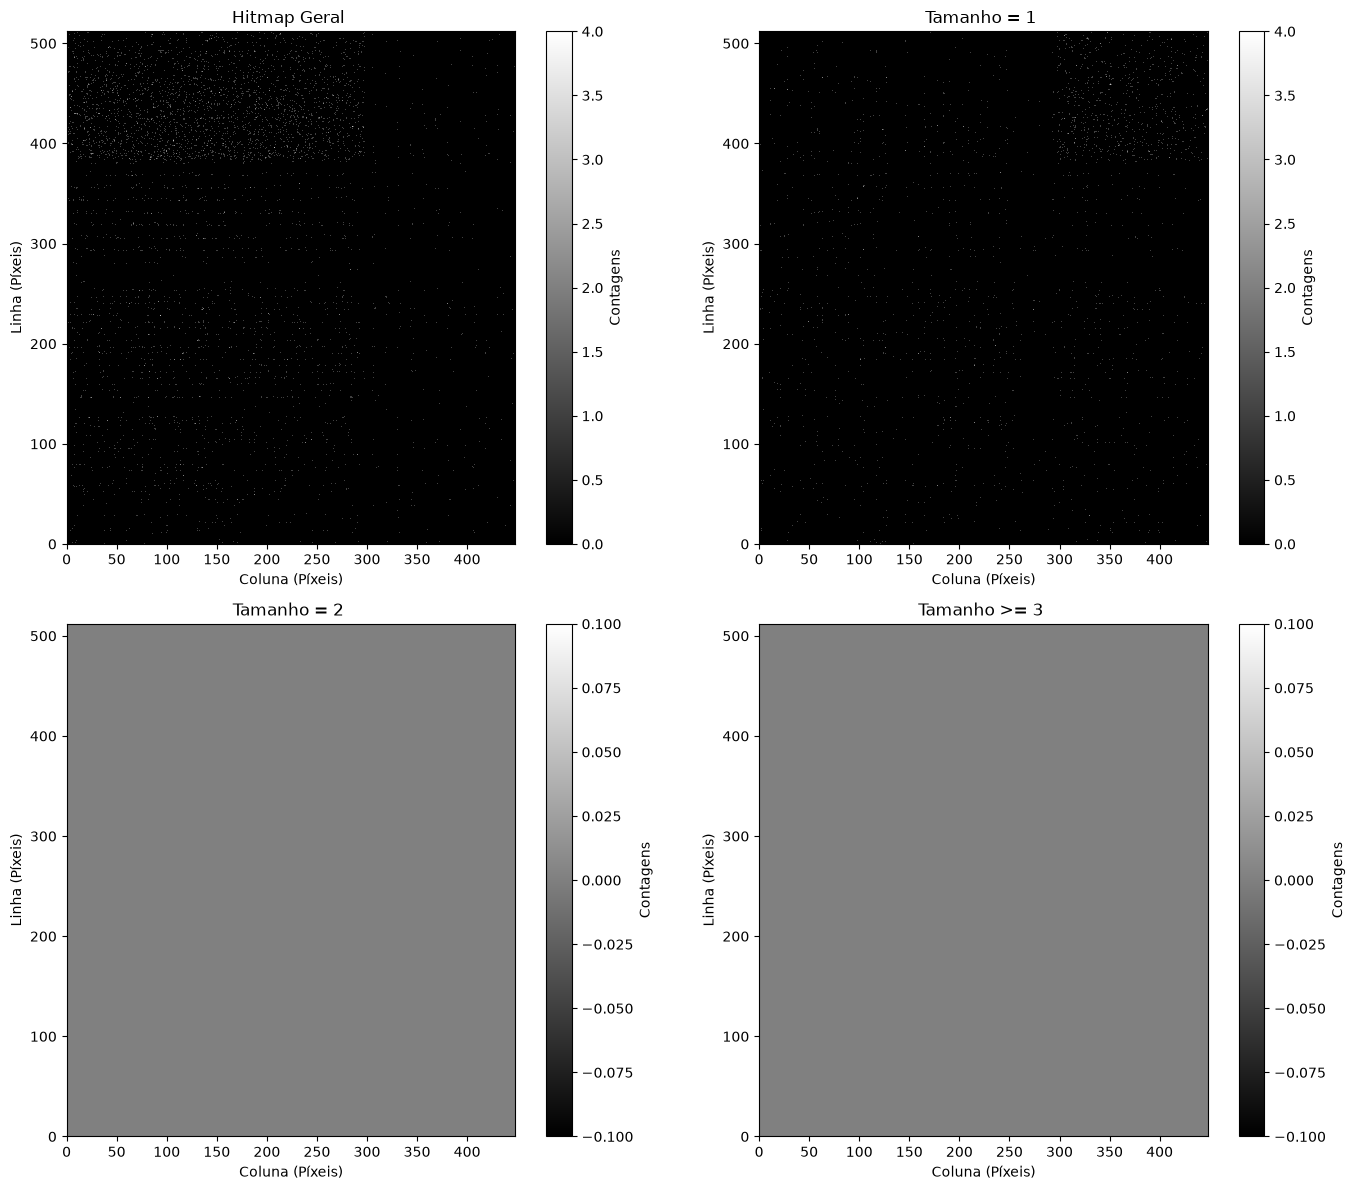

In [ ]:
import uproot
import matplotlib.pyplot as plt
import numpy as np


caminho_arquivo = "/mnt/c/Users/larag/Downloads/arquivo.root"
file = uproot.open(caminho_arquivo)
tree = file["clusterTree"]

pos_x = tree["xpos"].array(library="np")
pos_y = tree["ypos"].array(library="np")
tamanho = tree["nhits"].array(library="np")

#Remover NaNs
mascara = ~np.isnan(pos_x) & ~np.isnan(pos_y) & ~np.isnan(tamanho)
pos_x = pos_x[mascara]
pos_y = pos_y[mascara]
tamanho = tamanho[mascara]

# Converter de Milímetros para escala de Píxeis (Timepix4: pitch = 0.055 mm)
pitch_mm = 0.055
pos_x_pixel = pos_x / pitch_mm
pos_y_pixel = pos_y / pitch_mm


fator_subpixel = 2  
bins_x = 448 * fator_subpixel
bins_y = 512 * fator_subpixel
limites = [[0, 448], [0, 512]]


mask_1 = (tamanho == 1)
mask_2 = (tamanho == 2)
mask_3_mais = (tamanho >= 3)


def plotar_rapido(ax, x, y, titulo):
    # Calcula a matriz 2D rapidamente na memória sem gerar objetos pesados
    contagens, _, _ = np.histogram2d(x, y, bins=[bins_x, bins_y], range=limites)
    
    # Desenha a matriz como uma imagem bitmap leve (.T alinha os eixos X e Y)
    im = ax.imshow(contagens.T, origin='lower', extent=[0, 448, 0, 512], 
                   cmap='gray', aspect='equal', interpolation='nearest')
    ax.set_title(titulo)
    ax.set_xlabel('Coluna (Píxeis)')
    ax.set_ylabel('Linha (Píxeis)')
    plt.colorbar(im, ax=ax, label='Contagens')

fig, axs = plt.subplots(2, 2, figsize=(14, 12))

plotar_rapido(axs[0, 0], pos_x_pixel, pos_y_pixel, 'Hitmap Geral ')
plotar_rapido(axs[0, 1], pos_x_pixel[mask_1], pos_y_pixel[mask_1], 'Tamanho = 1 ')
plotar_rapido(axs[1, 0], pos_x_pixel[mask_2], pos_y_pixel[mask_2], 'Tamanho = 2 ')
plotar_rapido(axs[1, 1], pos_x_pixel[mask_3_mais], pos_y_pixel[mask_3_mais], 'Tamanho >= 3 ')

plt.tight_layout()
plt.show()